# TA-EVRP Run Analysis

Loads all completed runs from `runs/ta_evrp/` and compares metrics across planners and TRSP agents.

In [ ]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

RUNS_DIR = Path('../runs/ta_evrp')

## 1  Load Runs

In [2]:
def parse_run_id(run_id: str) -> dict:
    """Split 'planner_agent_YYYYMMDD_HHMMSS' into components."""
    # timestamp is always the last two underscore-separated tokens (date + time)
    parts = run_id.rsplit('_', 2)
    if len(parts) == 3:
        prefix, date, time = parts
        timestamp = f"{date}_{time}"
    else:
        prefix, timestamp = parts[0], '_'.join(parts[1:])
    # prefix is 'planner_agent' — split on first underscore
    idx = prefix.index('_')
    planner = prefix[:idx]
    agent   = prefix[idx+1:]
    return {'planner': planner, 'agent': agent, 'timestamp': timestamp}


def load_runs(runs_dir: Path) -> list[dict]:
    records = []
    for run_dir in sorted(runs_dir.iterdir()):
        if not run_dir.is_dir():
            continue
        metrics_file = run_dir / 'ta_evrp_metrics.json'
        instance_file = run_dir / 'generated_instance.json'
        if not metrics_file.exists():
            continue
        with metrics_file.open() as f:
            m = json.load(f)
        inst = {}
        if instance_file.exists():
            with instance_file.open() as f:
                inst = json.load(f)

        rec = parse_run_id(run_dir.name)
        rec['run_id'] = run_dir.name
        rec['run_dir'] = run_dir

        # top-level metrics
        rec.update({
            'makespan_s':              m.get('makespan_s'),
            'makespan_h':              m.get('makespan_h'),
            'total_distance_m':        m.get('total_distance_m'),
            'total_distance_km':       m.get('total_distance_km'),
            'total_energy_kwh':        m.get('total_energy_kwh'),
            'total_recharges':         m.get('total_recharges'),
            'customers_served':        m.get('customers_served'),
            'avg_inter_customer_gap_s': m.get('avg_inter_customer_gap_s'),
            'num_vehicles':            len(m.get('per_vehicle', {})),
        })

        rec['customer_completion_times_s'] = m.get('customer_completion_times_s', [])
        rec['per_vehicle'] = m.get('per_vehicle', {})

        # instance info
        gen = inst.get('generation_info', {})
        rec['num_customers'] = len(gen.get('customer_sumo_ids', []))
        rec['num_afs']       = len(gen.get('afs_sumo_ids', []))
        rec['depot_node']    = gen.get('depot_sumo_id', '?')
        rec['seed']          = gen.get('seed', '?')

        records.append(rec)
    return records


runs = load_runs(RUNS_DIR)
print(f"Loaded {len(runs)} run(s)")

Loaded 4 run(s)


## 2  Summary Table

In [3]:
display_cols = [
    'planner', 'agent', 'timestamp',
    'customers_served', 'num_vehicles', 'total_recharges',
    'makespan_s', 'makespan_h',
    'total_distance_km', 'total_energy_kwh',
    'avg_inter_customer_gap_s',
]

df = pd.DataFrame(runs)[display_cols].copy()
df = df.sort_values(['planner', 'agent', 'timestamp']).reset_index(drop=True)

df.style \
    .format({
        'makespan_s':              '{:.0f}',
        'makespan_h':              '{:.4f}',
        'total_distance_km':       '{:.3f}',
        'total_energy_kwh':        '{:.1f}',
        'avg_inter_customer_gap_s': '{:.1f}',
    }) \
    .background_gradient(subset=['makespan_s'], cmap='RdYlGn_r') \
    .background_gradient(subset=['total_distance_km'], cmap='RdYlGn_r') \
    .set_caption('All TA-EVRP Runs')

,planner,agent,timestamp,customers_served,num_vehicles,total_recharges,makespan_s,makespan_h,total_distance_km,total_energy_kwh,avg_inter_customer_gap_s
0,heuristic,dijkstra,20260428_184621,10,3,0,357,0.0992,14.788,498355.6,33.1
1,heuristic,sarsa,20260428_184641,10,3,0,361,0.1003,14.788,498355.6,33.6
2,milp,dijkstra,20260428_184449,10,1,1,948,0.2633,15.778,531705.1,98.8
3,milp,sarsa,20260428_184558,10,1,1,946,0.2628,15.778,531705.1,98.6


## 3  Per-Run Route Images

── heuristic_dijkstra_20260428_184621 ──


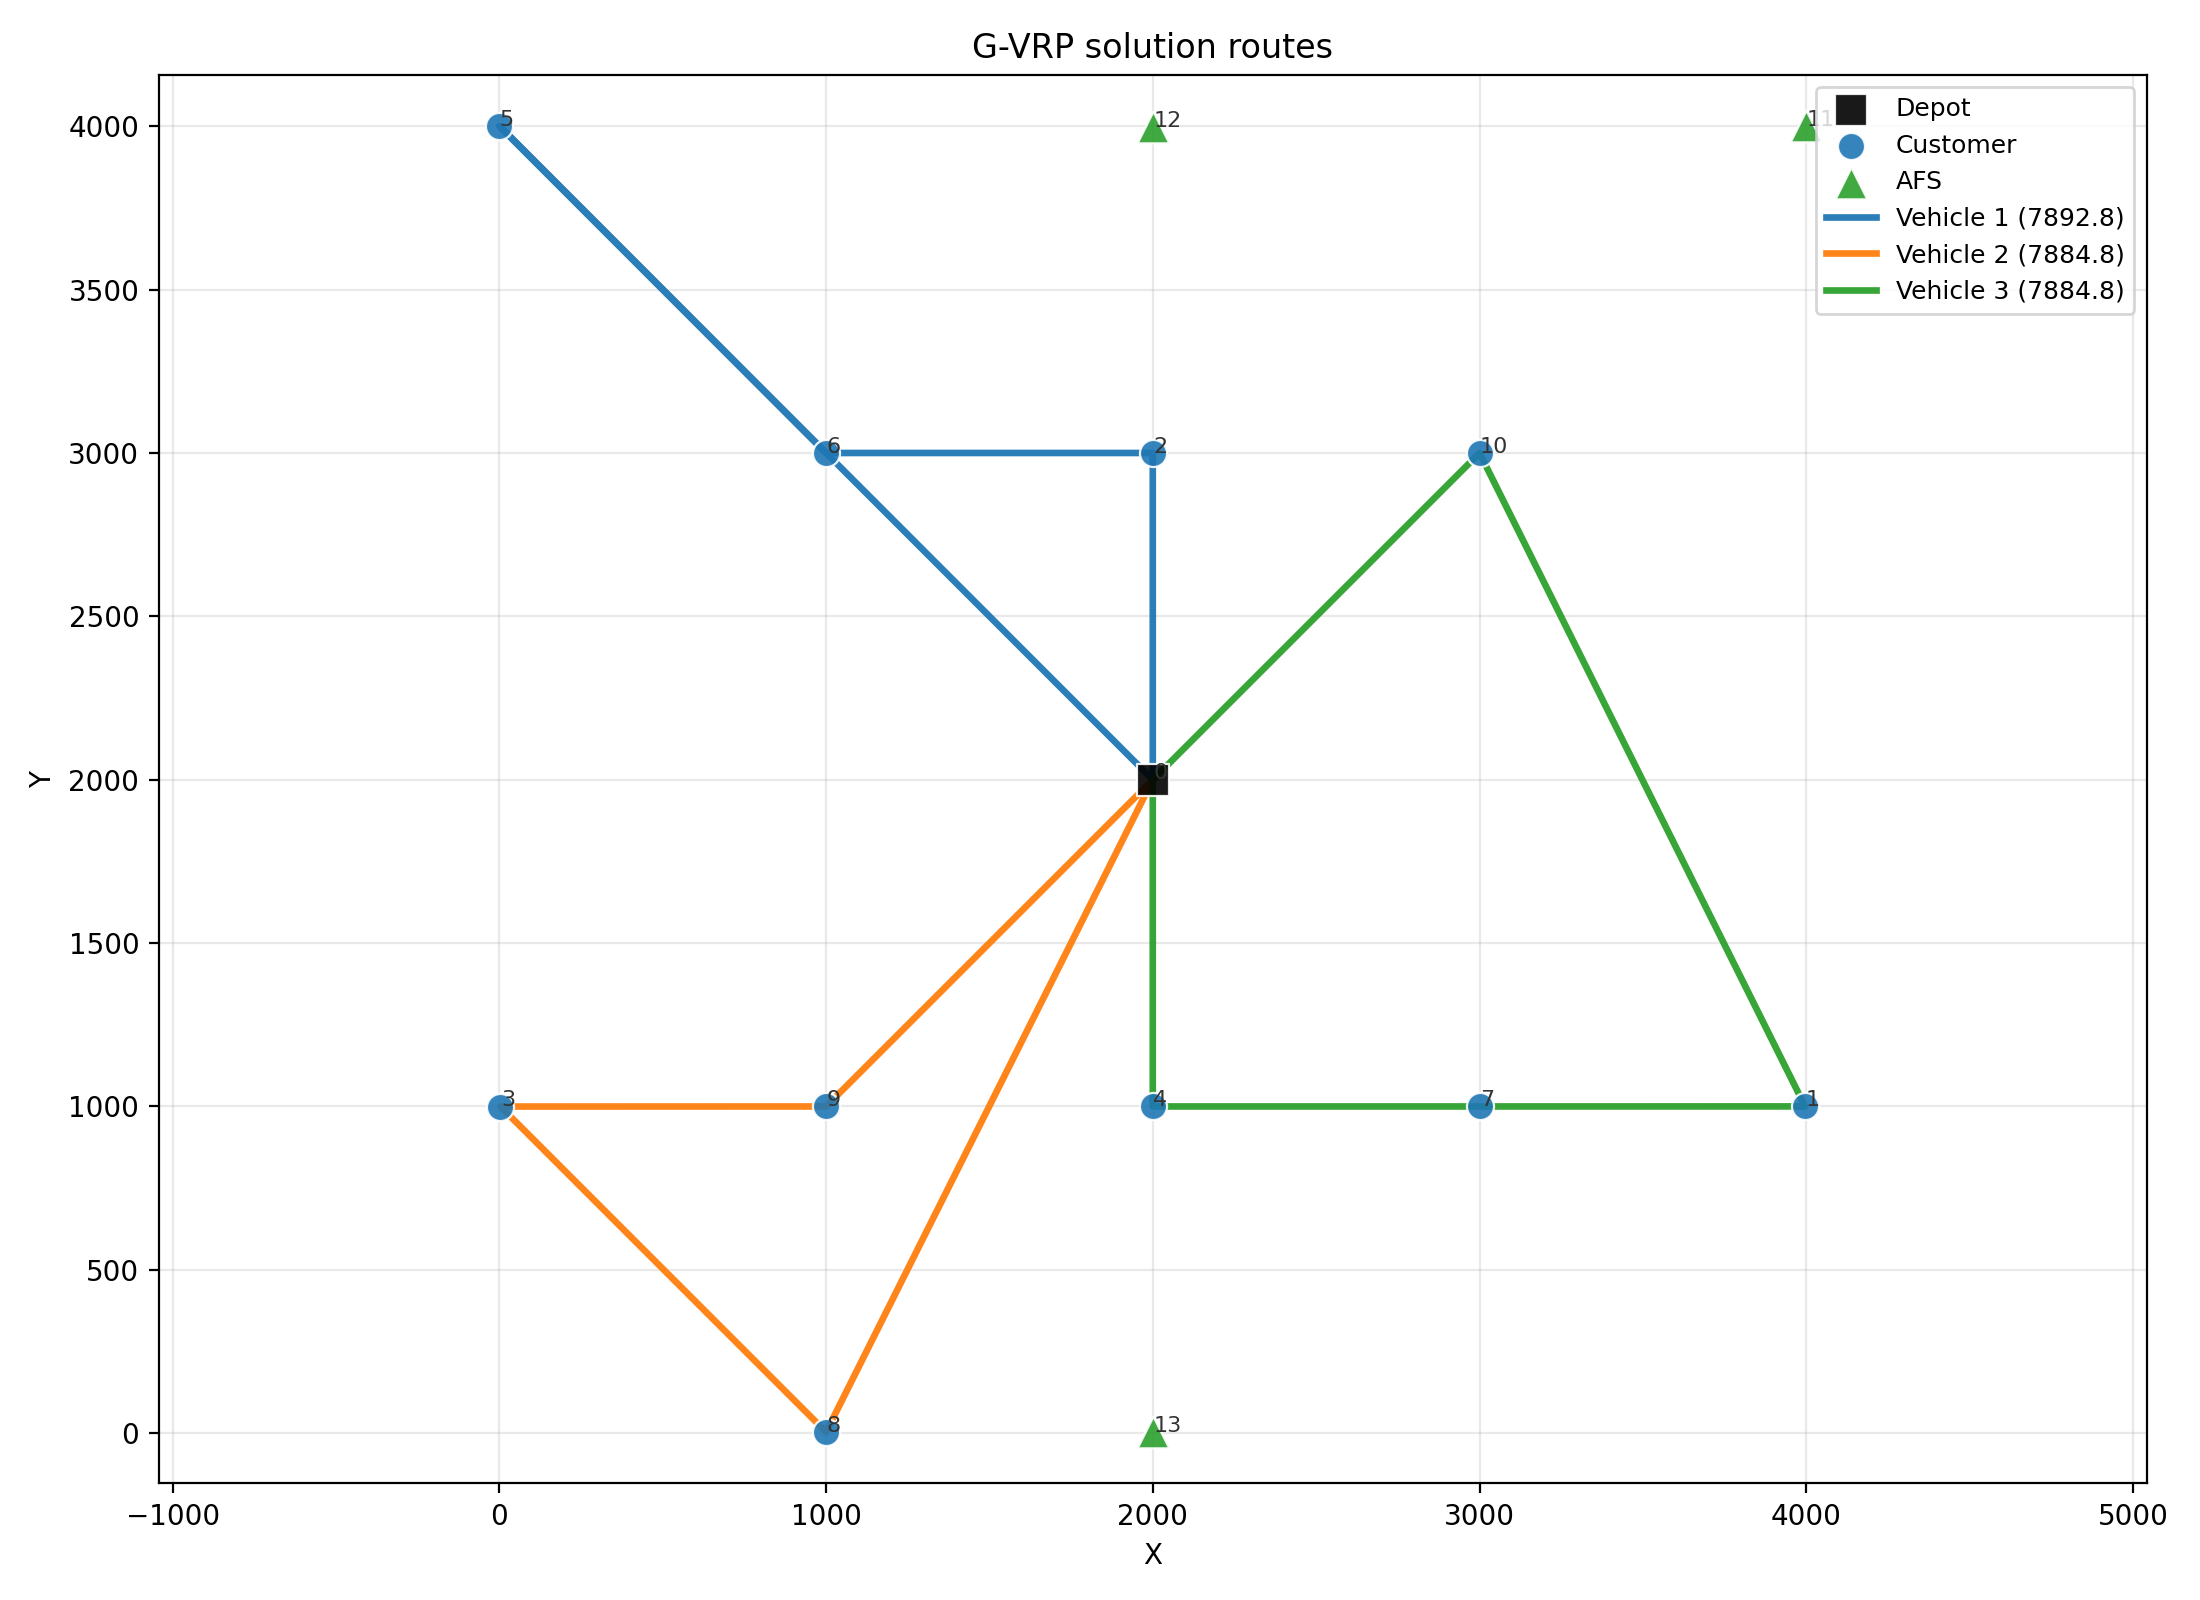

── heuristic_sarsa_20260428_184641 ──


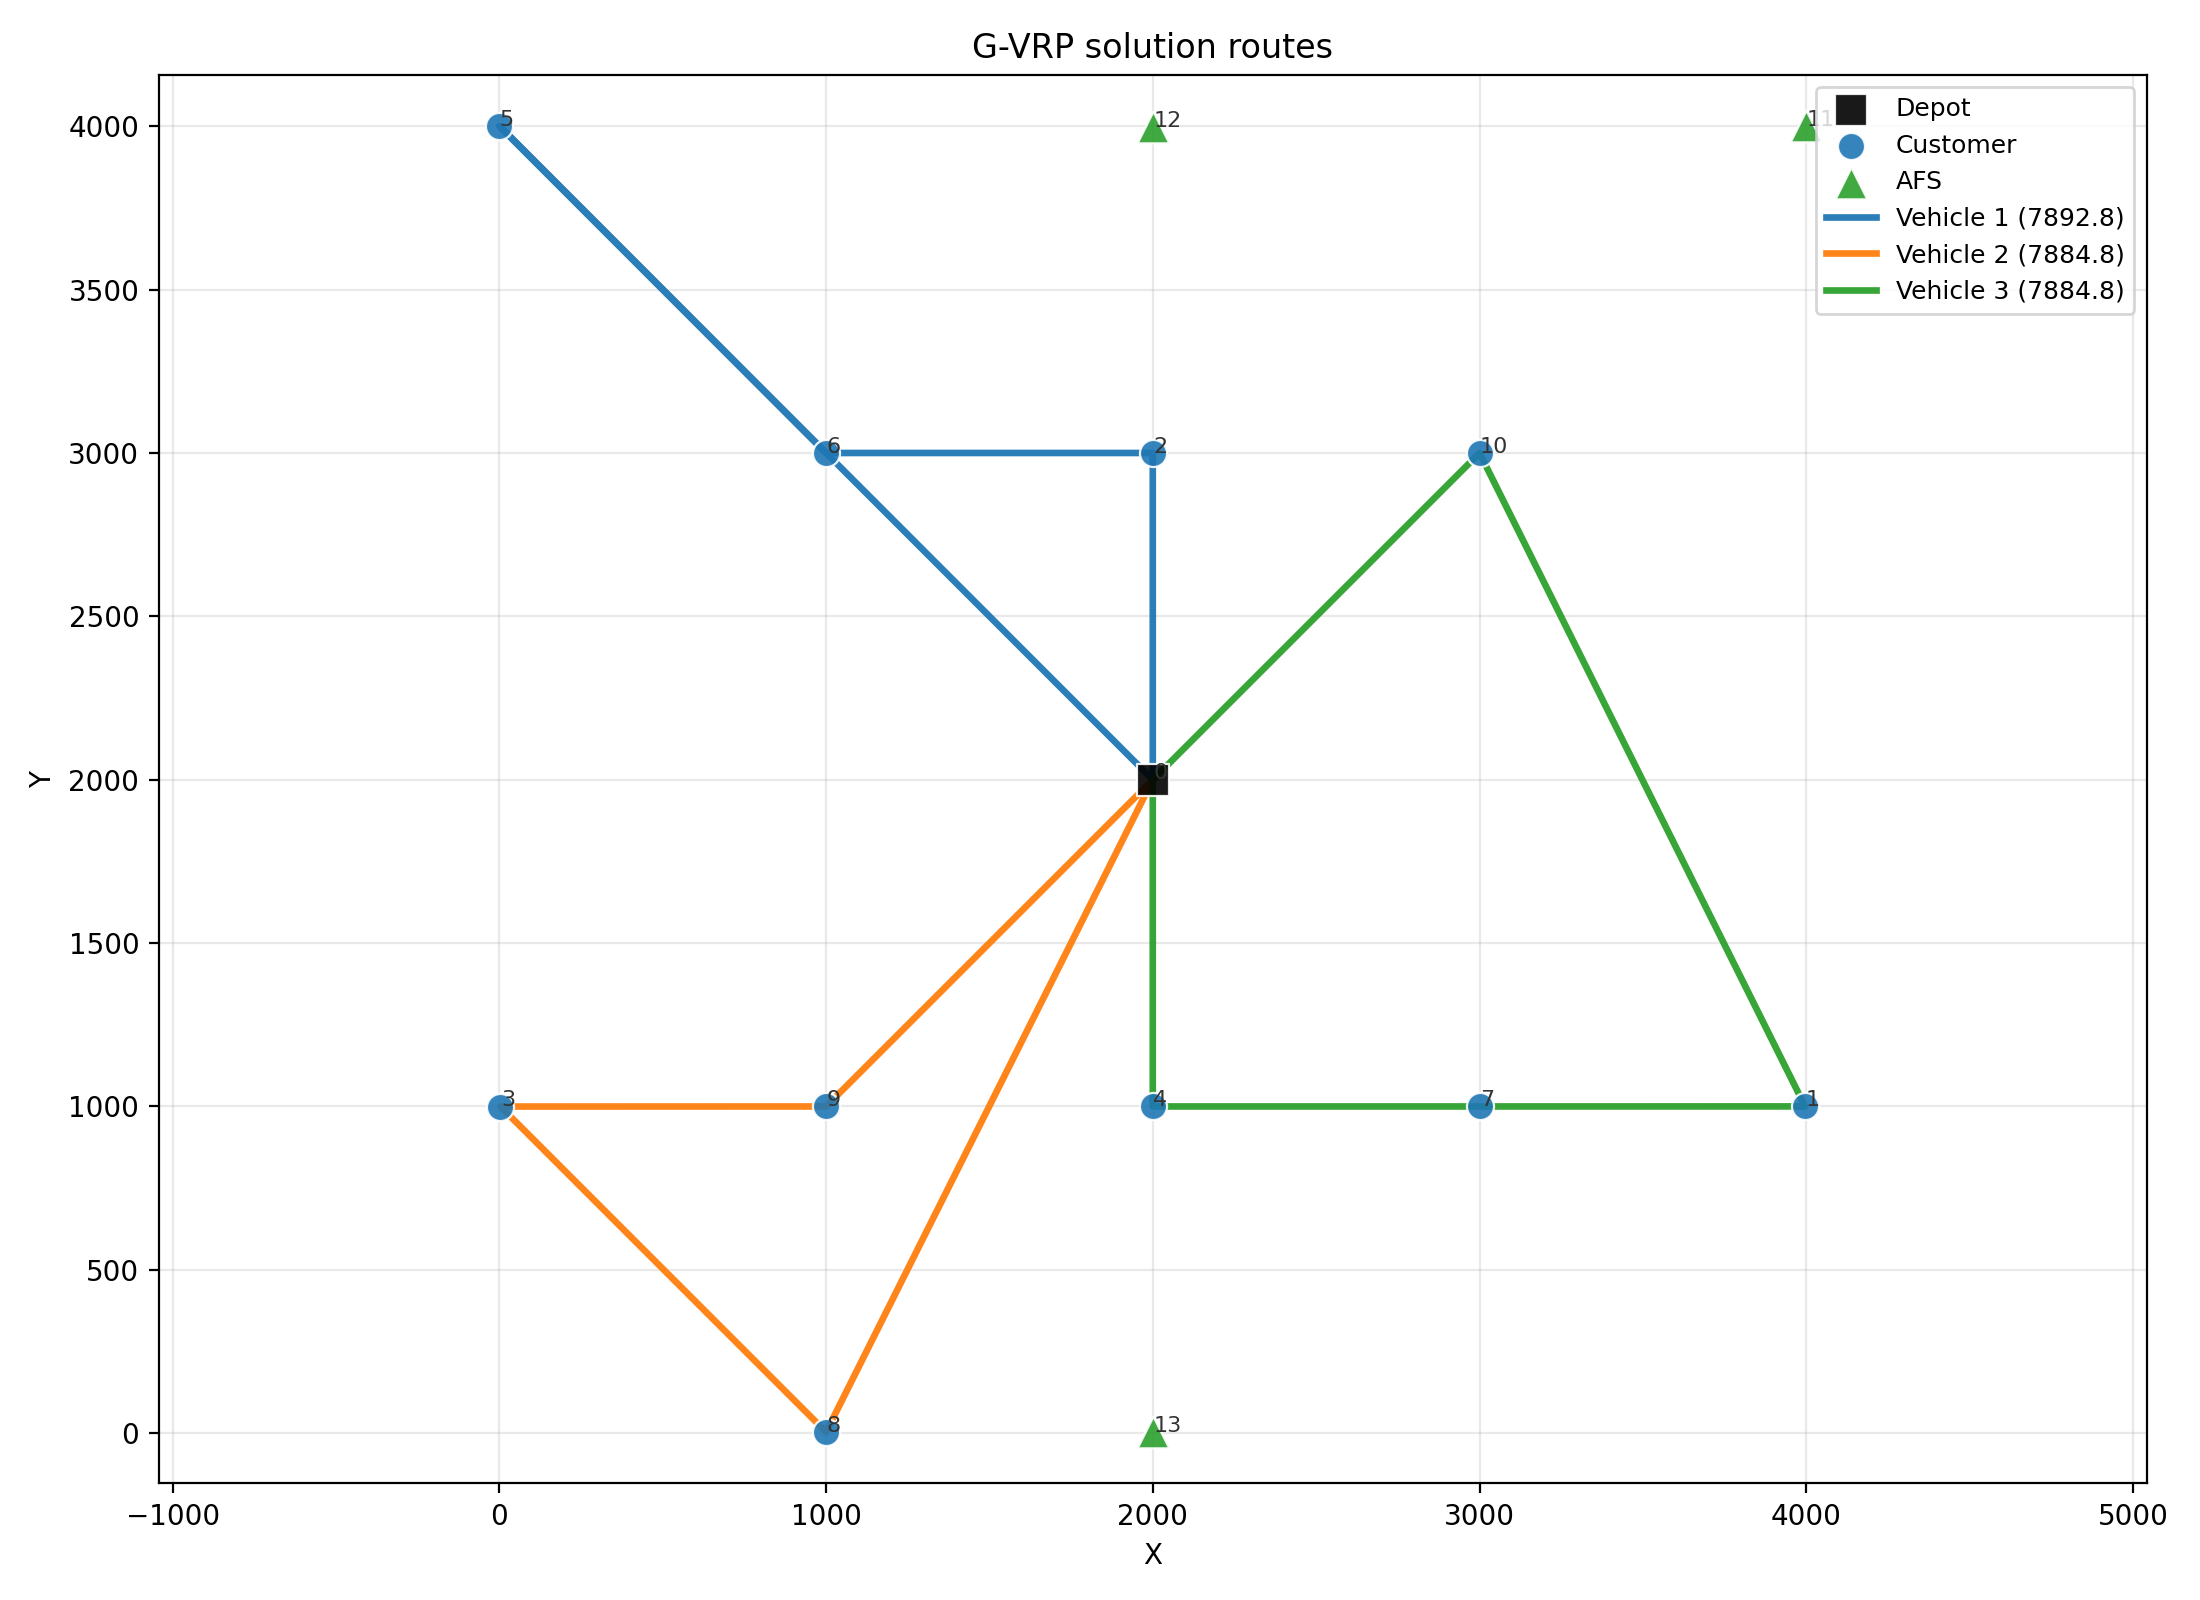

── milp_dijkstra_20260428_184449 ──


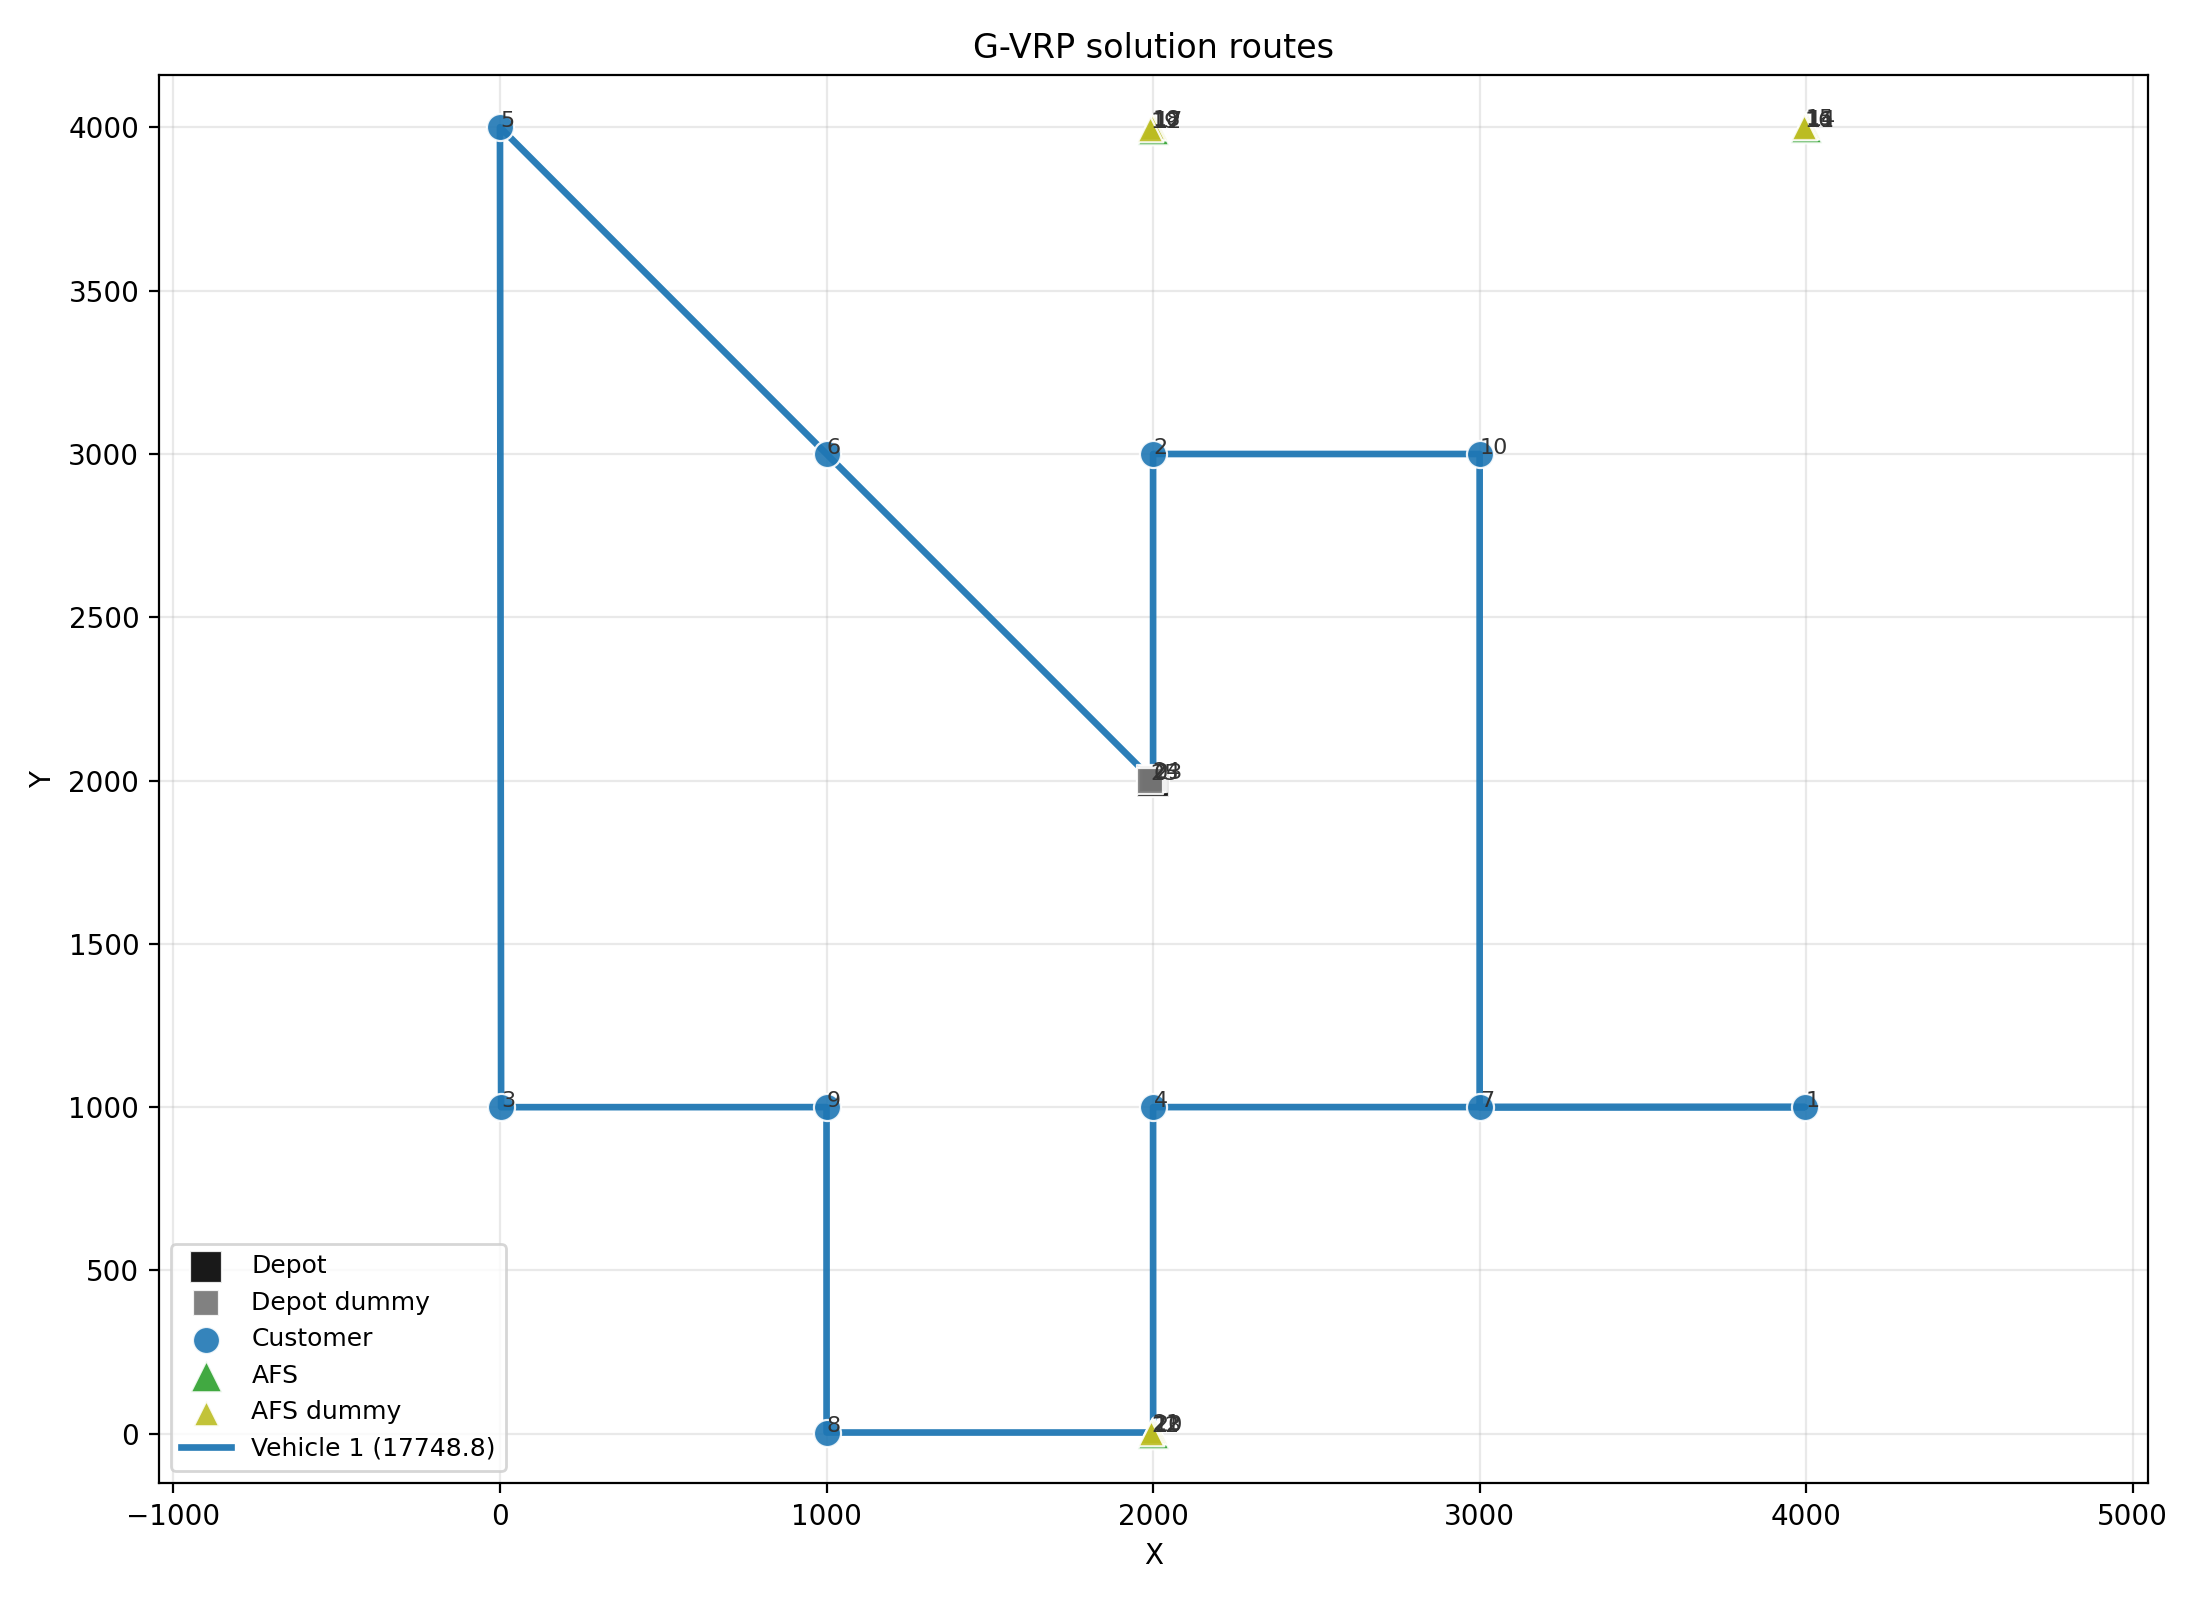

── milp_sarsa_20260428_184558 ──


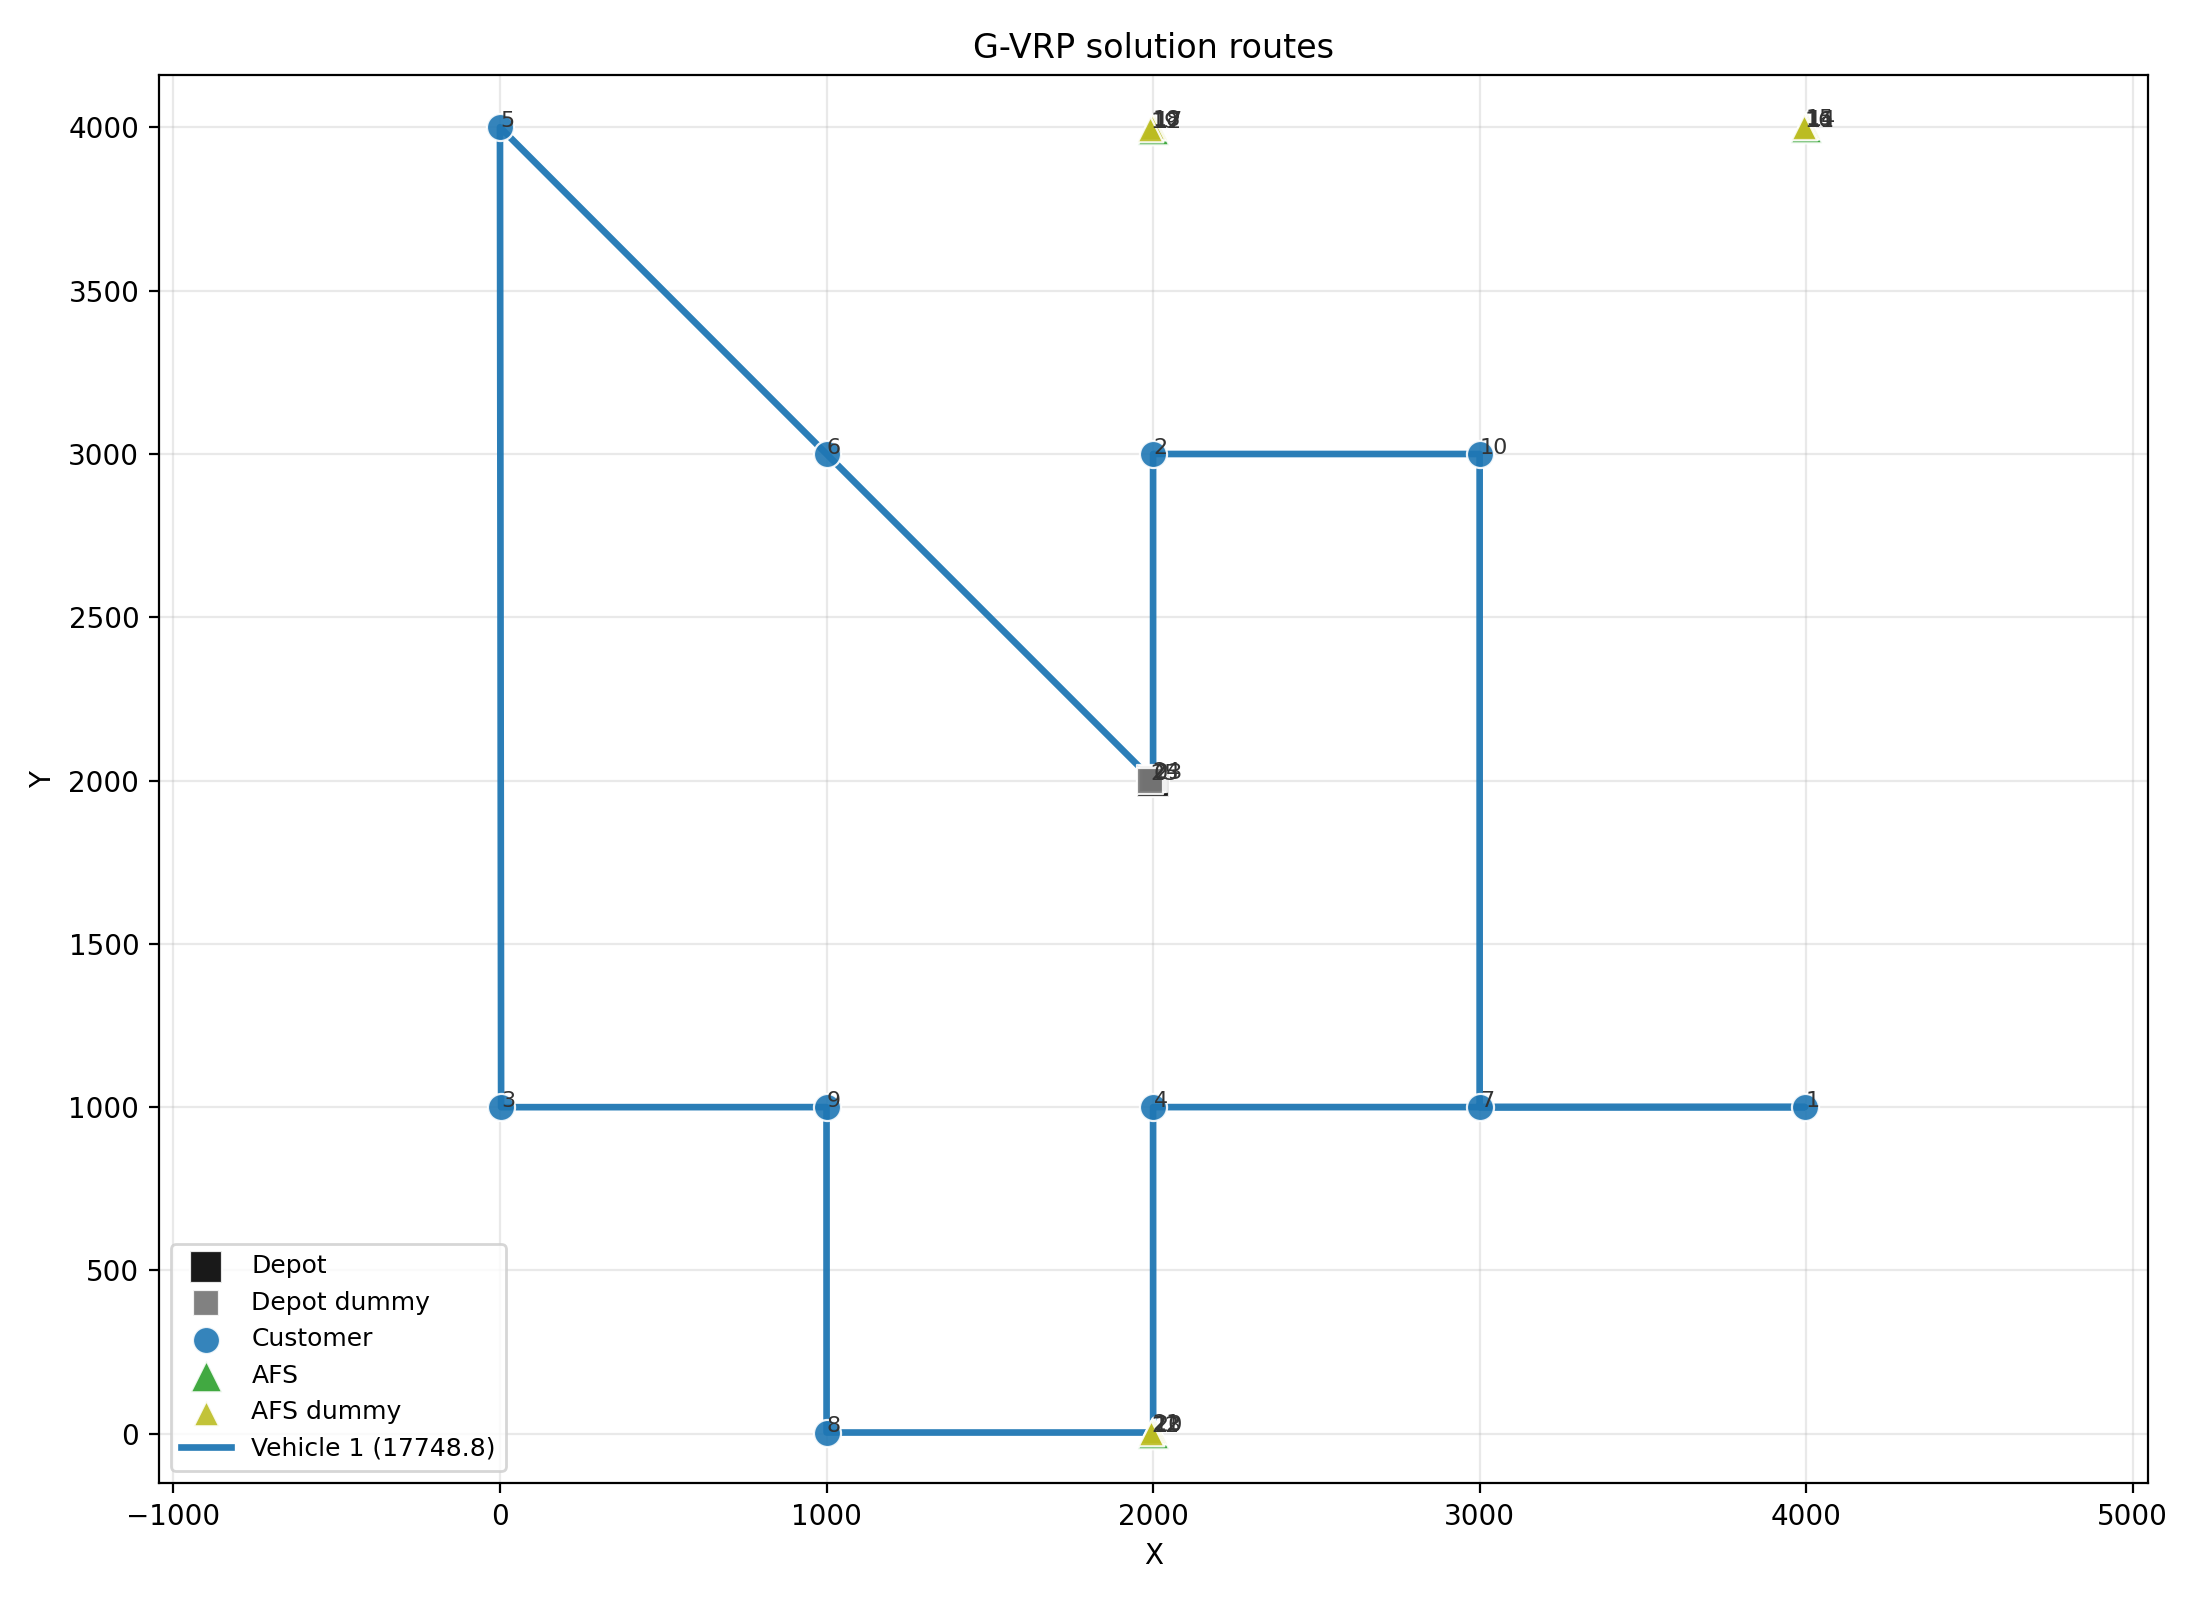

In [4]:
from IPython.display import display, Image

for rec in runs:
    img = rec['run_dir'] / 'gvrp_routes.png'
    if img.exists():
        print(f"── {rec['run_id']} ──")
        display(Image(str(img), width=700))

## 4  Metric Comparison Across Planners × Agents

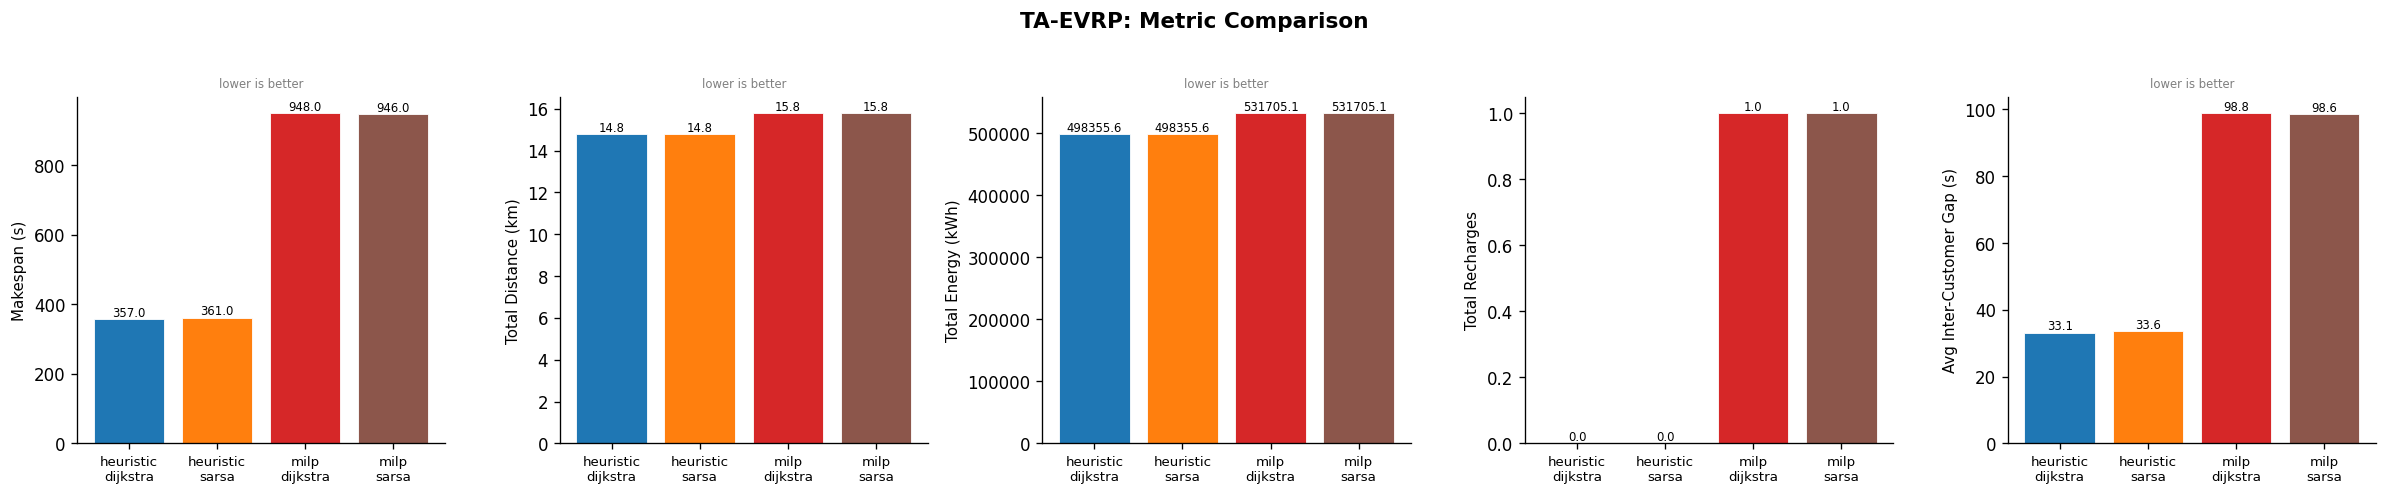

In [5]:
full_df = pd.DataFrame(runs)

METRICS = [
    ('makespan_s',              'Makespan (s)',             'lower is better'),
    ('total_distance_km',       'Total Distance (km)',      'lower is better'),
    ('total_energy_kwh',        'Total Energy (kWh)',       'lower is better'),
    ('total_recharges',         'Total Recharges',          ''),
    ('avg_inter_customer_gap_s','Avg Inter-Customer Gap (s)','lower is better'),
]

labels = [f"{r['planner']}\n{r['agent']}" for _, r in full_df.iterrows()]
colors = plt.cm.tab10(np.linspace(0, 0.5, len(full_df)))

fig, axes = plt.subplots(1, len(METRICS), figsize=(4 * len(METRICS), 4), sharey=False)
fig.suptitle('TA-EVRP: Metric Comparison', fontsize=13, fontweight='bold', y=1.02)

for ax, (col, ylabel, note) in zip(axes, METRICS):
    vals = full_df[col].tolist()
    bars = ax.bar(range(len(vals)), vals, color=colors, edgecolor='white', linewidth=0.5)
    ax.set_xticks(range(len(vals)))
    ax.set_xticklabels(labels, fontsize=8)
    ax.set_ylabel(ylabel, fontsize=9)
    if note:
        ax.set_title(note, fontsize=7, color='gray')
    for bar, val in zip(bars, vals):
        if val is not None:
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                    f'{val:.1f}', ha='center', va='bottom', fontsize=7)

plt.tight_layout()
plt.show()

## 5  Customer Completion Time Curves

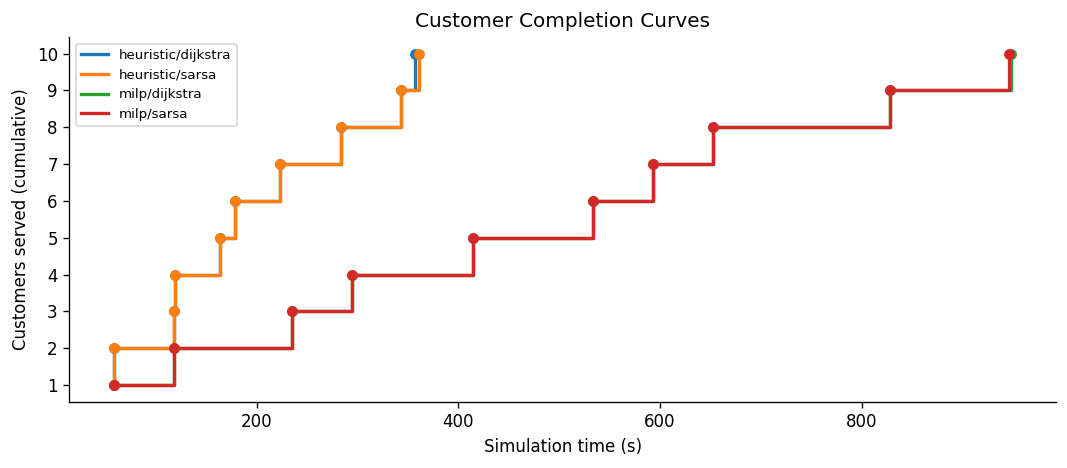

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))

for rec in runs:
    times = rec['customer_completion_times_s']
    if not times:
        continue
    label = f"{rec['planner']}/{rec['agent']}"
    xs = sorted(times)
    ys = list(range(1, len(xs) + 1))
    ax.step(xs, ys, where='post', label=label, linewidth=2)
    ax.scatter(xs, ys, s=30, zorder=5)

ax.set_xlabel('Simulation time (s)')
ax.set_ylabel('Customers served (cumulative)')
ax.set_title('Customer Completion Curves')
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6  Per-Vehicle Breakdown

In [7]:
veh_records = []
for rec in runs:
    for vid, vdata in rec['per_vehicle'].items():
        veh_records.append({
            'run_id':          rec['run_id'],
            'planner':         rec['planner'],
            'agent':           rec['agent'],
            'vehicle':         int(vid),
            'distance_m':      vdata['distance_m'],
            'energy_kwh':      vdata['energy_kwh'],
            'num_recharges':   vdata['num_recharges'],
            'customers_served': vdata['customers_served'],
            'finish_time_s':   vdata['finish_time_s'],
        })

vdf = pd.DataFrame(veh_records).sort_values(['planner', 'agent', 'vehicle'])

vdf.style \
    .format({
        'distance_m':    '{:.0f}',
        'energy_kwh':    '{:.1f}',
        'finish_time_s': '{:.0f}',
    }) \
    .background_gradient(subset=['finish_time_s'], cmap='RdYlGn_r') \
    .set_caption('Per-Vehicle Metrics')

,run_id,planner,agent,vehicle,distance_m,energy_kwh,num_recharges,customers_served,finish_time_s
0,heuristic_dijkstra_20260428_184621,heuristic,dijkstra,1,3946,132993.7,0,3,357
1,heuristic_dijkstra_20260428_184621,heuristic,dijkstra,2,4928,166073.6,0,3,357
2,heuristic_dijkstra_20260428_184621,heuristic,dijkstra,3,5914,199288.3,0,4,357
3,heuristic_sarsa_20260428_184641,heuristic,sarsa,1,3946,132993.7,0,3,361
4,heuristic_sarsa_20260428_184641,heuristic,sarsa,2,4928,166073.6,0,3,361
5,heuristic_sarsa_20260428_184641,heuristic,sarsa,3,5914,199288.3,0,4,361
6,milp_dijkstra_20260428_184449,milp,dijkstra,1,15778,531705.1,1,10,948
7,milp_sarsa_20260428_184558,milp,sarsa,1,15778,531705.1,1,10,946


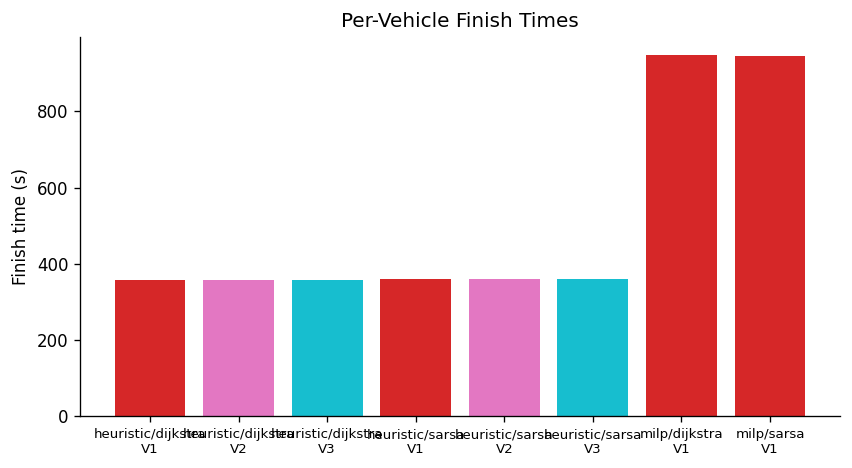

In [8]:
# If multiple vehicles per run: grouped bar chart of finish times
if vdf['vehicle'].nunique() > 1:
    fig, ax = plt.subplots(figsize=(max(7, len(vdf) * 0.9), 4))
    run_labels = vdf.apply(lambda r: f"{r['planner']}/{r['agent']}\nV{r['vehicle']}", axis=1)
    ax.bar(range(len(vdf)), vdf['finish_time_s'], color=plt.cm.tab10(vdf['vehicle'] / vdf['vehicle'].max()))
    ax.set_xticks(range(len(vdf)))
    ax.set_xticklabels(run_labels, fontsize=8)
    ax.set_ylabel('Finish time (s)')
    ax.set_title('Per-Vehicle Finish Times')
    plt.tight_layout()
    plt.show()
else:
    print('Single-vehicle runs — finish time is identical to makespan.')

## 7  Planner × Agent Pivot (best run per combination)

In [9]:
# When multiple runs exist for the same (planner, agent), keep the latest.
latest = (
    full_df
    .sort_values('timestamp')
    .groupby(['planner', 'agent'], as_index=False)
    .last()
)

for metric, label, _ in METRICS:
    pivot = latest.pivot(index='planner', columns='agent', values=metric)
    print(f'\n── {label} ──')
    display(pivot.style.format('{:.2f}').background_gradient(cmap='RdYlGn_r', axis=None))


── Makespan (s) ──


agent,dijkstra,sarsa
planner,,
heuristic,357.00,361.00
milp,948.00,946.00



── Total Distance (km) ──


agent,dijkstra,sarsa
planner,,
heuristic,14.79,14.79
milp,15.78,15.78



── Total Energy (kWh) ──


agent,dijkstra,sarsa
planner,,
heuristic,498355.60,498355.60
milp,531705.12,531705.12



── Total Recharges ──


agent,dijkstra,sarsa
planner,,
heuristic,0.00,0.00
milp,1.00,1.00



── Avg Inter-Customer Gap (s) ──


agent,dijkstra,sarsa
planner,,
heuristic,33.11,33.56
milp,98.78,98.56


## 8  Instance Summary

In [10]:
inst_cols = ['run_id', 'planner', 'agent', 'seed', 'num_customers', 'num_afs', 'depot_node', 'num_vehicles']
pd.DataFrame(runs)[inst_cols]

,run_id,planner,agent,seed,num_customers,num_afs,depot_node,num_vehicles
0,heuristic_dijkstra_20260428_184621,heuristic,dijkstra,42,10,3,C2,3
1,heuristic_sarsa_20260428_184641,heuristic,sarsa,42,10,3,C2,3
2,milp_dijkstra_20260428_184449,milp,dijkstra,42,10,3,C2,1
3,milp_sarsa_20260428_184558,milp,sarsa,42,10,3,C2,1
